# Baseline Models
**IST 707 – Applied Machine Learning · Final Project**

---

This notebook builds the two baselines for predicting whether a hard drive fails in the next 30 days
(Tasks 5 and 6 in `WORKPLAN.md`). They are the reference points the final tuned model has to beat.

- **Baseline 1, no training:** flag a drive if any sectors have been reallocated (`smart_5_raw_last > 0`).
  This is the rule operators use today.
- **Baseline 2, trained:** a plain logistic regression with default regularization and no hyperparameter search.

| § | Section | Purpose |
|---|---|---|
| 1 | Setup | Libraries and data loading (train and calib only) |
| 2 | Baseline 1: SMART 5 rule | Operating point of the rule on calib |
| 3 | Baseline 2: features | Which columns go into the logistic regression and why |
| 4 | Baseline 2: pipeline | Imputation, scaling and encoding |
| 5 | Time-aware validation | Fit on older windows, check on the most recent ones |
| 6 | Calibration set | Ranking at a replacement budget, threshold choice, recalibration |
| 7 | Summary | Baseline numbers to carry forward |

**How the splits are used** (per `WORKPLAN.md`): train for fitting, calib for evaluation at true prevalence and
for choosing any threshold. `modeling_test.parquet` is **not** opened here, per the data snooping rule.

## 1. Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (precision_score, recall_score, f1_score, average_precision_score,
                             precision_recall_curve)

pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
DATA_DIR = "../data/modeling"
SEED = 42
BUDGETS = [1, 2, 5, 10]   # drives replaced per 1,000

def vendor(model: str) -> str:
    m = str(model)
    if m.startswith("ST"): return "Seagate"
    if m.startswith("TOSHIBA"): return "Toshiba"
    if m.startswith(("WDC", "WUH")): return "WDC"
    if m.startswith(("HGST", "Hitachi")): return "HGST"
    return "Other"

### 1.1 Loading the data
Train is sampled to 20:1 (healthy:failing). Calib holds November and December 2024 at the true prevalence
(about 1 in 905). Both load in full.

In [2]:
train = pd.read_parquet(f"{DATA_DIR}/modeling_train.parquet")
calib = pd.read_parquet(f"{DATA_DIR}/modeling_calib.parquet")

for d in (train, calib):
    d["capacity_bytes"] = d["capacity_bytes"].replace(-1, np.nan)   # -1 is Backblaze's "unknown"
    d["vendor"] = d["model"].map(vendor)

for name, d in [("train", train), ("calib", calib)]:
    print(f"{name:>5}: {len(d):>7,} rows | {int(d.label.sum()):>5,} failures | 1 in {len(d)/d.label.sum():,.0f} | windows {d.window.min()}–{d.window.max()}")

y_cal = calib["label"].values

train: 169,827 rows | 8,087 failures | 1 in 21 | windows 0–21
calib: 297,009 rows |   328 failures | 1 in 906 | windows 22–23


## 2. Baseline 1: SMART 5 Rule (no training)

The rule flags every drive with at least one reallocated sector. Nothing is fit, so it is scored directly on
calib at true prevalence. The rule gives a yes/no answer rather than a ranking, so its PR-AUC is computed
from the 0/1 flag.

In [3]:
rule_flag = (calib["smart_5_raw_last"] > 0).astype(int).values

rule = {
    "flagged per 1,000": 1000 * rule_flag.mean(),
    "recall": recall_score(y_cal, rule_flag),
    "precision": precision_score(y_cal, rule_flag),
    "F1": f1_score(y_cal, rule_flag),
    "PR-AUC (0/1 score)": average_precision_score(y_cal, rule_flag),
}
pd.DataFrame([rule], index=["Baseline 1: smart_5_raw_last > 0"])

,"flagged per 1,000",recall,precision,F1,PR-AUC (0/1 score)
Baseline 1: smart_5_raw_last > 0,41.6957,0.5030,0.0133,0.0260,0.0073


**Interpretation.** The rule catches about half of upcoming failures, but it flags about 42 of every 1,000 drives,
and only about 1 in 75 of those actually fails. Its budget is fixed by the data, not chosen by the operator.

## 3. Baseline 2: Features

What goes into the logistic regression, following the data card, the EDA conclusions and report §9:

- **Raw SMART attributes** (first, last, delta for each). The EDA showed raw values carry more failure signal
  than the vendor-normalized ones.
- **Normalized SMART attributes are dropped**, since they mostly encode the manufacturer.
- **SMART 4 is dropped**: it is almost perfectly correlated with SMART 12 (ρ = 0.997).
- **Vendor and capacity instead of drive model** (report §9.3). Train holds 63 of 72 drive models and most
  2025 drives were never seen in train, so a one-hot of `model` would not generalize. Vendor is
  one-hot encoded; capacity is numeric.
- **`days_observed`, `days_span`**: how much of the window the drive actually reported.
- **Not used:** the five bookkeeping columns (`serial_number`, `window`, `window_first_date`,
  `window_last_date`, `label`), `model`, and `drive_days_to_date`, which counts days since 2023-01-01 and so
  tracks the calendar rather than the drive.

In [4]:
RAW_SMART = [c for c in train.columns
             if c.startswith("smart_") and "_raw_" in c and not c.startswith("smart_4_")]
NUM_COLS = RAW_SMART + ["capacity_bytes", "days_observed", "days_span"]
CAT_COLS = ["vendor"]
FEATURES = NUM_COLS + CAT_COLS

print(f"{len(RAW_SMART)} raw SMART features + 3 numeric descriptors + vendor ({train.vendor.nunique()} categories)")

39 raw SMART features + 3 numeric descriptors + vendor (4 categories)


## 4. Baseline 2: Pipeline

Logistic regression is sensitive to scale and cannot take missing values, so every numeric column goes through:

1. **Median imputation with a missing-value indicator.** S197 is missing only for two Toshiba models that do
   not report it (report §9.2). Its median is 0, so imputation alone would read "not reported" as "healthy". The
   indicator adds a separate "not reported" flag, so the model can tell the two apart.
2. **Signed log transform**, `sign(x)·log(1+|x|)`. Raw counters span many orders of magnitude, and deltas can
   be negative.
3. **Standard scaling**, fit on the training rows only.

The classifier uses scikit-learn defaults (`C = 1.0`, L2 penalty) and no class weights.

In [5]:
def signed_log(X):
    return np.sign(X) * np.log1p(np.abs(X))

def make_baseline():
    numeric = Pipeline([
        ("impute", SimpleImputer(strategy="median", add_indicator=True)),
        ("log", FunctionTransformer(signed_log)),
        ("scale", StandardScaler()),
    ])
    pre = ColumnTransformer([
        ("num", numeric, NUM_COLS),
        ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_COLS),
    ])
    return Pipeline([("pre", pre), ("clf", LogisticRegression(max_iter=2000, random_state=SEED))])

make_baseline()

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('pre', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of 

## 5. Time-aware Validation

A random split would put a drive's earlier windows in fitting and its later windows in validation, which leaks.
The model is fit on **windows 0–16** and checked on **windows 18–21**, the most recent four months of train.

**Window 17 is left out as a gap.** A window's label reads the next window, so window 17's label covers the
same days as window 18's features. Dropping it keeps fit and validation apart, as the real splits do.

This fold is still sampled 20:1, so it is only a sanity check that the model learns real signal. All decisions
are made on calib in §6.

In [6]:
fit_mask = train.window <= 16
val_mask = train.window >= 18
X_fit, y_fit = train.loc[fit_mask, FEATURES], train.loc[fit_mask, "label"]
X_val, y_val = train.loc[val_mask, FEATURES], train.loc[val_mask, "label"]
print(f"fit: {len(X_fit):,} rows ({y_fit.sum():,} failures) | validation: {len(X_val):,} rows ({y_val.sum():,} failures)")

lr = make_baseline().fit(X_fit, y_fit)
p_val = lr.predict_proba(X_val)[:, 1]

def scores(y, pred, prob=None):
    out = {"recall": recall_score(y, pred), "precision": precision_score(y, pred), "F1": f1_score(y, pred)}
    if prob is not None:
        out["PR-AUC"] = average_precision_score(y, prob)
    return out

pd.DataFrame([scores(y_val, p_val >= 0.5, p_val)], index=["validation (20:1) @ 0.50"])

fit: 128,057 rows (6,076 failures) | validation: 33,501 rows (1,604 failures)


,recall,precision,F1,PR-AUC
validation (20:1) @ 0.50,0.3940,0.7332,0.5126,0.5542


**Interpretation.** On the 20:1 fold the model ranks failing drives well above healthy ones (PR-AUC far above
the 0.048 base rate). These numbers do not carry over to the real fleet, where failures are about 43 times
rarer, so they are not the headline result.

## 6. Calibration Set: Performance at True Prevalence

The model is refit on all of train (windows 0–21) and scored on calib.

In [7]:
lr_full = make_baseline().fit(train[FEATURES], train["label"])
p_cal = lr_full.predict_proba(calib[FEATURES])[:, 1]
print(f"PR-AUC on calib: logistic regression {average_precision_score(y_cal, p_cal):.4f} | "
      f"SMART 5 rule {rule['PR-AUC (0/1 score)']:.4f} | random {y_cal.mean():.4f}")

PR-AUC on calib: logistic regression 0.0818 | SMART 5 rule 0.0073 | random 0.0011


### 6.1 Precision and recall at a replacement budget (primary metric)

Operators replace a fixed number of drives, so the model ranks drives by risk and the top N per thousand are
flagged. No threshold is needed.

For comparison at the same budget:
- **SMART 5 rule:** it flags about 42 per 1,000, more than any budget here. Choosing N of its flagged drives at
  random gives its precision unchanged and its recall scaled by N / 42.
- **Random:** precision equals the failure rate and recall equals N / 1,000.

The last row scores the logistic regression at the rule's own budget, a direct comparison.

In [8]:
order = np.argsort(-p_cal)
n_fail, n_rule = y_cal.sum(), rule_flag.sum()
rule_prec = y_cal[rule_flag == 1].mean()
rule_budget = 1000 * rule_flag.mean()

rows = []
for per_k in BUDGETS + [rule_budget]:
    n = int(len(p_cal) * per_k / 1000)
    caught = y_cal[order[:n]].sum()
    frac = min(n / n_rule, 1.0)
    rows.append({
        "budget (per 1,000)": f"{per_k:.1f} (rule's own)" if per_k == rule_budget else str(per_k),
        "drives flagged": n,
        "LR precision": caught / n, "LR recall": caught / n_fail,
        "rule precision": rule_prec, "rule recall": rule["recall"] * frac,
        "random precision": y_cal.mean(), "random recall": n / len(p_cal),
    })
budget_table = pd.DataFrame(rows).set_index("budget (per 1,000)")
budget_table

,drives flagged,LR precision,LR recall,rule precision,rule recall,random precision,random recall
"budget (per 1,000)",,,,,,,
1,297,0.1582,0.1433,0.0133,0.0121,0.0011,0.0010
2,594,0.1162,0.2104,0.0133,0.0241,0.0011,0.0020
5,1485,0.0721,0.3262,0.0133,0.0603,0.0011,0.0050
10,2970,0.0495,0.4482,0.0133,0.1206,0.0011,0.0100
41.7 (rule's own),12384,0.0175,0.6616,0.0133,0.5030,0.0011,0.0417


**Interpretation.** At every budget the logistic regression's precision is several times the rule's, and at the
rule's own budget it catches more failures than the rule does. Ranking by predicted risk is what makes the
difference: the most at-risk drives are flagged first, while the rule treats one reallocated sector the same as
thousands.

### 6.2 Threshold choice and recalibration on calib

Picking a threshold and recalibrating are both fit on data, so they need a separate set to check on. Calib is
split **50/50 by drive**: half A chooses the threshold and fits the recalibration, half B checks them.
Splitting by window would not work: window 22 holds only 3,783 rows and 7 failures, and almost all of calib
falls in window 23.

- **Threshold:** the value that maximizes F1 on half A.
- **Recalibration (Platt scaling):** training at 20:1 inflates every predicted probability. A one-feature
  logistic regression on the model's log-odds, fit on half A, maps scores back to the true failure rate.

In [9]:
idx_a, idx_b = next(GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=SEED)
                    .split(calib, groups=calib["serial_number"]))
print(f"half A: {len(idx_a):,} rows ({y_cal[idx_a].sum()} failures) | half B: {len(idx_b):,} rows ({y_cal[idx_b].sum()} failures)")

prec, rec, thr = precision_recall_curve(y_cal[idx_a], p_cal[idx_a])
f1 = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
THRESHOLD = float(thr[np.argmax(f1)])

thr_table = pd.DataFrame([
    scores(y_cal[idx_b], p_cal[idx_b] >= 0.5),
    scores(y_cal[idx_b], p_cal[idx_b] >= THRESHOLD),
    scores(y_cal[idx_b], rule_flag[idx_b]),
], index=["LR @ 0.50 (half B)", f"LR @ {THRESHOLD:.3f}, chosen on half A (half B)", "SMART 5 rule (half B)"])
thr_table

half A: 148,531 rows (166 failures) | half B: 148,478 rows (162 failures)


,recall,precision,F1
LR @ 0.50 (half B),0.4074,0.0585,0.1023
"LR @ 0.917, chosen on half A (half B)",0.2346,0.1131,0.1526
SMART 5 rule (half B),0.5309,0.0139,0.0271


half B actual failure rate      : 0.00109
mean predicted, before recalib. : 0.03077  (28.2x too high)
mean predicted, after recalib.  : 0.00116  (1.1x)


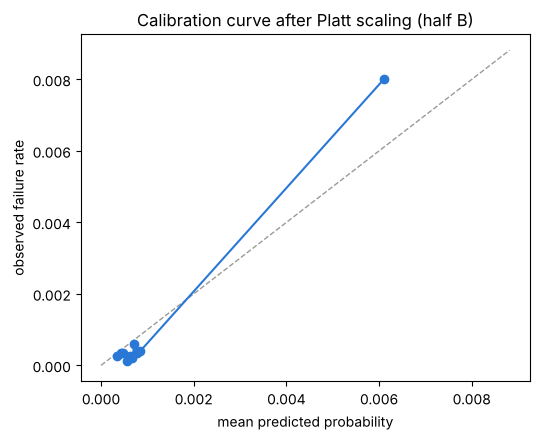

In [10]:
def logit(p):
    p = np.clip(p, 1e-9, 1 - 1e-9)
    return np.log(p / (1 - p)).reshape(-1, 1)

platt = LogisticRegression().fit(logit(p_cal[idx_a]), y_cal[idx_a])
p_recal = platt.predict_proba(logit(p_cal[idx_b]))[:, 1]

actual = y_cal[idx_b].mean()
print(f"half B actual failure rate      : {actual:.5f}")
print(f"mean predicted, before recalib. : {p_cal[idx_b].mean():.5f}  ({p_cal[idx_b].mean() / actual:.1f}x too high)")
print(f"mean predicted, after recalib.  : {p_recal.mean():.5f}  ({p_recal.mean() / actual:.1f}x)")

bins = pd.qcut(p_recal, 10, duplicates="drop")
rel = pd.DataFrame({"pred": p_recal, "obs": y_cal[idx_b]}).groupby(bins, observed=True).mean()
fig, ax = plt.subplots(figsize=(5.5, 4.5))
lim = max(rel.pred.max(), rel.obs.max()) * 1.1
ax.plot([0, lim], [0, lim], ls="--", color="#9a9a96", lw=1)
ax.plot(rel.pred, rel.obs, "-o", color="#2a78d6")
ax.set_xlabel("mean predicted probability"); ax.set_ylabel("observed failure rate")
ax.set_title("Calibration curve after Platt scaling (half B)"); plt.tight_layout(); plt.show()

**Interpretation.** A threshold chosen at true prevalence is much higher than one chosen on the 20:1 fold, and
it trades recall for precision. F1 stays low for both baselines, because healthy drives outnumber failing ones
about 900 to 1. Before recalibration the model's average predicted risk is many times the real failure rate.
Platt scaling brings it close to the observed rate on half B, so recalibrated scores can be read as risk.

## 7. Summary

| | Baseline 1 | Baseline 2 |
|---|---|---|
| Model | `smart_5_raw_last > 0` | Logistic regression, default `C = 1.0`, no tuning |
| Fitting | None | Train, all windows (0–21) |
| Features | SMART 5 only | Raw SMART first/last/delta (minus SMART 4), capacity, days observed/span, vendor |

Primary results on calib at true prevalence: PR-AUC, and precision/recall at fixed replacement budgets.

In [11]:
summary = pd.DataFrame({
    "PR-AUC": [average_precision_score(y_cal, p_cal), rule["PR-AUC (0/1 score)"], y_cal.mean()],
    **{f"precision @ {k}/1k": [budget_table.loc[str(k), c] for c in ["LR precision", "rule precision", "random precision"]] for k in BUDGETS},
    **{f"recall @ {k}/1k": [budget_table.loc[str(k), c] for c in ["LR recall", "rule recall", "random recall"]] for k in BUDGETS},
}, index=["Baseline 2: logistic regression", "Baseline 1: SMART 5 rule", "Random"])
display(summary.T)

print("Secondary, F1 at a threshold (calib half B):")
display(thr_table.iloc[1:])

,Baseline 2: logistic regression,Baseline 1: SMART 5 rule,Random
PR-AUC,0.0818,0.0073,0.0011
precision @ 1/1k,0.1582,0.0133,0.0011
precision @ 2/1k,0.1162,0.0133,0.0011
precision @ 5/1k,0.0721,0.0133,0.0011
precision @ 10/1k,0.0495,0.0133,0.0011
recall @ 1/1k,0.1433,0.0121,0.0010
recall @ 2/1k,0.2104,0.0241,0.0020
recall @ 5/1k,0.3262,0.0603,0.0050
recall @ 10/1k,0.4482,0.1206,0.0100


Secondary, F1 at a threshold (calib half B):


,recall,precision,F1
"LR @ 0.917, chosen on half A (half B)",0.2346,0.1131,0.1526
SMART 5 rule (half B),0.5309,0.0139,0.0271


**What the final model has to improve on.** The logistic regression already beats the rule at every budget,
but at 10 per 1,000 it still misses over half of failures, and most of the drives it flags are healthy. The final
model (XGBoost with tuning, then calibration) is judged against these numbers.